# DGT 야드 장치 기간 상관분석 · 수정 보고서
**SKP K 뉴딜 아카데미 부산항만 데이터분석과정 · 2025년 DGT 자부두환적 표본**

## 1. 분석 목적과 지표

이번 분석에서는 **본선작업완료지연시간**과 **야드 장치 기간**의 관계를 확인한다.
기존 보고서의 작업시작 대기시간은 작업시작시각이 확인되는 일부 항차에서만 산출할 수 있어,
전체 자부두환적 표본의 분석 범위를 유지하기 위해 이번 보고서의 변수에서 제외했다.
일부 항차의 분석 자체가 무의미하다는 뜻은 아니며, 전체 표본에 대한 대표성의 한계를 고려한 범위 조정이다.

|역할|변수|계산식|
|---|---|---|
|독립변수 X|본선작업완료지연시간|항차별 마지막컨테이너작업완료일시 − 반입마감일시|
|종속변수 Y|야드 장치 기간|반출일시 − 장치일시|

마지막 작업완료 시각은 **DGT_2025_anmual.csv의 전체 컨테이너 명세**에서 구한다.
운송수단이 선박(S)인 양하 작업의 `in.inDate`와 적하 작업의 `out.outDate`를
각각 해당 모선항차에 연결하고, 동일 항차에서 가장 늦은 시각을 사용한다.
수출·수입·환적 여부로 마지막 작업의 집계 대상을 제한하지 않는다.
반입마감일시는 DGT 선석배정현황에서 가져온다.

야드 장치 기간과 화물 특성은 DGT_SELF_TS.csv의 자부두환적 표본을 사용한다.
컨테이너 반입·반출과 양하·적하모선의 실제 입항·접안·출항이 모두 2025년인 경우만 포함한다.
시간 단위는 시간, 물동량은 20ft=1 TEU, 40ft=2 TEU, 45ft=2.25 TEU다.
건수는 표본 크기의 설명에 사용하며 컨테이너당 기술통계와 TEU 가중평균을 함께 제시한다.
**모든 물동량·장치기간·상관분석의 대상은 이 자부두환적 표본으로 한정한다.**
선석별 물동량과 적컨·공컨·냉동·위험물별 분석도 동일 표본만 사용한다.
`DGT_2025_anmual.csv`는 항차 전체의 마지막 컨테이너 작업완료일시 계산에만 사용한다.


### 가설과 분석단위

H₀: 본선작업완료지연시간과 야드 장치 기간의 상관이 0이다.

같은 적하모선의 컨테이너들은 본선작업완료지연시간을 공유하므로,
검정에서는 **적하모선항차당 한 점**을 사용한다.
종속변수는 해당 항차에 연결된 컨테이너의 **TEU 가중평균 야드 장치 기간**이다.
TEU를 독립 표본으로 복제하지 않는다. 컨테이너당 기술통계는 별도로 제시한다.

전체 표본의 단일 지표에 대해 Pearson r·Spearman rho, 양측 p값, 단변량 R²를 산출한다.
전체 분석은 설명변수 하나이므로 지표 간 다중검정 보정을 적용하지 않는다.
선석별 3개, 화물별 4개의 층별 검정은 각 묶음에서 Pearson·Spearman별로 Holm 보정한다.
유의수준은 0.05다. 다음 입항 지연을 추가 변수로 측정하지 않으므로 전파 사슬 전체의 검증으로 해석하지 않는다.


In [1]:
from pathlib import Path
import os, re, json, hashlib, platform, importlib.metadata as metadata
paths=[Path.cwd(),*Path.cwd().parents]
DATA=next((p if (p/'DGT_SELF_TS.csv').exists() else p/'analysis'
           for p in paths if (p/'DGT_SELF_TS.csv').exists() or (p/'analysis'/'DGT_SELF_TS.csv').exists()),None)
if DATA is None: raise FileNotFoundError('analysis 폴더에 두 원자료를 배치하세요.')
OUT=DATA/'dgt_correlation_modified_outputs'
OUT.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'.runtime'/'matplotlib')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown, HTML

for p in [Path('C:/Windows/Fonts/malgun.ttf'),Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc')]:
    if p.exists(): font_manager.fontManager.addfont(str(p))
names={f.name for f in font_manager.fontManager.ttflist}
FONT=next((f for f in ['Noto Sans CJK KR','Noto Sans CJK JP','Malgun Gothic','Apple SD Gothic Neo','NanumGothic'] if f in names),None)
if FONT is None: raise RuntimeError('한글 폰트를 설치하세요: Noto Sans CJK KR 또는 맑은 고딕')
sns.set_theme(style='whitegrid',font=FONT,rc={'axes.unicode_minus':False,'figure.dpi':110})
plt.rcParams['axes.unicode_minus']=False
X1='본선작업완료지연시간'
Y='야드 장치 기간'

def dt(s):
    return pd.to_datetime(s.astype('string').str.strip().replace({'':pd.NA,'-':pd.NA}),format='mixed',errors='coerce')
def h(end,start): return (end-start).dt.total_seconds()/3600
def call(value):
    m=re.fullmatch(r'\s*([A-Za-z0-9]+)-(\d+)/(\d{4})\s*',str(value))
    return f'{m[1].upper()}-{int(m[2]):03d}/{m[3]}' if m else None
def table(frame,title):
    print(title)
    formats={c:(lambda v:f'{v:.3g}') if 'p' in c else (lambda v:f'{v:,.3f}') for c in frame.select_dtypes('float').columns}
    display(HTML(frame.to_html(index=False,formatters=formats,na_rep='—',border=0)))
    frame.to_csv(OUT/(re.sub(r'[^\w가-힣]+','_',title)+'.csv'),index=False,encoding='utf-8-sig')
TEU_MAP={20:1.0,40:2.0,45:2.25}  # 45ft 환산은 사용자 지정


## 2. 원자료 정리와 2025년 필터링

선박 일정 JSON은 컨테이너에 기록된 모선항차와 정확히 일치하는 응답만 연결한다.
실제 시각은 CSV의 선박 일정에서 가져오고, Excel의 예정시각으로 실제값을 대체하지 않는다.
동일 모선항차의 응답 충돌이나 선석배정현황 중복이 있으면 임의 선택 없이 중단한다.

In [2]:
csv_path=DATA/'DGT_SELF_TS.csv'
xlsx_path=DATA/'DGT_2025_선석배정현황.xlsx'
raw=pd.read_csv(csv_path,dtype=str,keep_default_na=False)
mapping={'컨테이너번호':'컨테이너번호','DGT_방문회차':'방문회차','판정':'환적판정',
         '명세.in.mode':'반입운송수단','명세.out.mode':'반출운송수단',
         '명세.in.vvd':'양하모선항차','명세.out.vvd':'적하모선항차',
         '명세.in.inDate':'반입일시','명세.in.stackDate':'장치일시','명세.out.outDate':'반출일시','명세.length':'규격'}
cnt=raw[list(mapping)].rename(columns=mapping).copy()
cnt.insert(0,'원자료행',np.arange(2,len(cnt)+2))
for c in ['양하모선항차','적하모선항차']: cnt[c]=cnt[c].map(call)
for c in ['반입일시','장치일시','반출일시']: cnt[c]=dt(cnt[c])
cnt['TEU']=pd.to_numeric(cnt['규격'],errors='coerce').map(TEU_MAP)
cnt[Y]=h(cnt['반출일시'],cnt['장치일시'])

records=[]
fields={'ata':'실제 입항일시','atb':'실제 접안일시','atd':'실제 출항일시','berthNo':'선석'}
for side,source in [('양하','반입선박일정'),('적하','반출선박일정')]:
    for i,r in raw.iterrows():
        wanted=cnt.loc[i,side+'모선항차']
        responses=json.loads(r[f'상세.{source}.response.vesselSchedules'] or '[]')
        found=[s for s in responses if call(f"{s['vesselCode']}-{s['voyageSeq']}/{s['voyageYear']}")==wanted]
        if len(found)!=1: raise ValueError(f'원자료행 {i+2}: 선박 일정 응답 연결 불가')
        records.append({'모선항차':wanted,**{label:found[0].get(key) for key,label in fields.items()}})
ships=pd.DataFrame(records)
assert not ships.groupby('모선항차')[list(fields.values())].nunique(dropna=False).gt(1).any().any()
ships=ships.drop_duplicates('모선항차').copy()
for c in ['실제 입항일시','실제 접안일시','실제 출항일시']: ships[c]=dt(ships[c])
ships['선석']=ships['선석'].astype('string').str.extract(r'^(B[123])',expand=False)
actual=['실제 입항일시','실제 접안일시','실제 출항일시']
ships['실제시각_2025']=ships[actual].apply(lambda s:s.dt.year.eq(2025)).all(axis=1)
ships['실제시각_순서정상']=ships['실제 입항일시'].le(ships['실제 접안일시']) & ships['실제 접안일시'].le(ships['실제 출항일시'])

sch=pd.read_excel(xlsx_path,sheet_name='2025 선석배정현황',dtype=str).fillna('')
sch['모선항차']=sch['모선항차(선사항차)'].str.split('(').str[0].str.strip().map(call)
sch=sch.rename(columns={'반입마감시간':'반입마감일시'})
assert sch['모선항차'].notna().all() and not sch.duplicated('모선항차').any()
sch['반입마감일시']=dt(sch['반입마감일시'])

# 항차별 마지막 작업완료 시각 계산에만 연간 자료를 사용한다. 물동량 표본으로 사용하지 않는다.
annual_candidates=[DATA/'DGT_2025_anmual.csv',DATA.parent/'data'/'DATA2'/'DGT_2025_anmual.csv',
                   DATA/'data'/'DATA2'/'DGT_2025_anmual.csv']
annual_path=next((p for p in annual_candidates if p.exists()),None)
if annual_path is None: raise FileNotFoundError('DGT_2025_anmual.csv를 analysis 또는 data/DATA2에 배치하세요.')
annual_columns=['cntrNo','point','in.mode','in.vvd','in.inDate','out.mode','out.vvd','out.outDate']
annual=pd.read_csv(annual_path,dtype=str,keep_default_na=False,usecols=annual_columns)
annual['양하모선항차']=annual['in.vvd'].map(call)
annual['적하모선항차']=annual['out.vvd'].map(call)
annual['반입일시']=dt(annual['in.inDate'])
annual['반출일시']=dt(annual['out.outDate'])
print('전체 컨테이너 명세 원자료:',len(annual),'행')


전체 컨테이너 명세 원자료: 919084 행


### 항차별 마지막 작업완료 시각의 집계 범위

`DGT_2025_anmual.csv`의 전체 컨테이너 명세를 사용한다. 수출·수입·환적을 구분하지 않고,
양하모선항차의 선박(S) 반입일시와 적하모선항차의 선박(S) 반출일시를 같은 항차에 모아 최댓값을 계산한다.
육상(R) 반입·반출은 본선 작업에서 제외하며, 같은 컨테이너 방문회차·항차·작업방향의 반복 명세는 한 번만 집계한다.
연도 경계의 마지막 작업을 잘라내지 않도록 이 최댓값은 연간 파일의 제공 시각 전체에서 먼저 계산한다.

`DGT_SELF_TS.csv`는 2025년 자부두환적 표본의 야드 장치 기간과 화물 특성을 분석하는 데 사용한다.
이 표본의 반출 최댓값을 항차 전체의 마지막 작업시각으로 사용하지 않는다.
연간 파일에서도 누락된 작업이 있다면 최댓값이 실제 마지막 작업보다 이를 수 있으므로,
관측된 전체 명세의 최댓값이라는 자료 범위를 함께 명시한다.

In [3]:
self_mask=(cnt['환적판정'].eq('SELF') & cnt['반입운송수단'].eq('S') & cnt['반출운송수단'].eq('S')
           & cnt['양하모선항차'].notna() & cnt['적하모선항차'].notna() & cnt['양하모선항차'].ne(cnt['적하모선항차']))
assert not cnt.loc[self_mask].duplicated(['컨테이너번호','방문회차']).any()
# 수출입·환적 구분 없이 연간 전체 자료의 선박(S) 작업을 모은다.
# 육상(R) 반입·반출은 본선 작업완료 시각에 포함하지 않는다.
unloading=annual.loc[annual['in.mode'].eq('S'),['cntrNo','point','양하모선항차','반입일시']].rename(
    columns={'양하모선항차':'모선항차','반입일시':'컨테이너작업완료일시'})
unloading['작업구분']='양하'
loading=annual.loc[annual['out.mode'].eq('S'),['cntrNo','point','적하모선항차','반출일시']].rename(
    columns={'적하모선항차':'모선항차','반출일시':'컨테이너작업완료일시'})
loading['작업구분']='적하'
events_raw=pd.concat([unloading,loading],ignore_index=True)
event_missing=int(events_raw[['모선항차','컨테이너작업완료일시']].isna().any(axis=1).sum())
events=events_raw.dropna(subset=['모선항차','컨테이너작업완료일시']).copy()
# 컨테이너·방문회차·항차·작업방향이 같은 명세의 반복 수집을 중복 집계하지 않는다.
event_key=['cntrNo','point','모선항차','작업구분']
assert not events.groupby(event_key)['컨테이너작업완료일시'].nunique().gt(1).any(), '동일 작업의 완료시각 충돌'
event_duplicates=int(events.duplicated(event_key).sum())
events=events.drop_duplicates(event_key).copy()
last=events.groupby('모선항차',as_index=False).agg(
    마지막컨테이너작업완료일시=('컨테이너작업완료일시','max'),
    마지막시각집계_연간작업건수=('컨테이너작업완료일시','count'))
operation=sch[['모선항차','반입마감일시']].merge(
    last,on='모선항차',how='inner',validate='one_to_one')
operation['적하모선항차']=operation['모선항차']
print('누락 작업:',event_missing,'/ 중복 작업:',event_duplicates,'/ 연간 명세의 고유 본선 작업:',len(events))
operation[X1]=h(operation['마지막컨테이너작업완료일시'],operation['반입마감일시'])

joined=cnt.copy()
for side in ['양하','적하']:
    part=ships.rename(columns={c:(side+'모선항차' if c=='모선항차' else side+'_'+c) for c in ships})
    joined=joined.merge(part,on=side+'모선항차',how='left',validate='many_to_one')
checks=[('자부두 환적',self_mask),
        ('컨테이너 반입·반출 모두 2025년',joined['반입일시'].dt.year.eq(2025)&joined['반출일시'].dt.year.eq(2025)),
        ('양하·적하모선 실제 시각 모두 2025년',joined['양하_실제시각_2025'].eq(True)&joined['적하_실제시각_2025'].eq(True)),
        ('선박 실제 시각 순서 정상',joined['양하_실제시각_순서정상'].eq(True)&joined['적하_실제시각_순서정상'].eq(True)),
        ('장치기간·규격 확인',joined[Y].ge(0)&joined['반출일시'].ge(joined['반입일시'])&joined['TEU'].notna())]
mask=pd.Series(True,index=joined.index)
flow=[{'선정 단계':'원자료','표본수':len(joined),'물동량(TEU)':joined['TEU'].sum()}]
for label,condition in checks:
    mask &= condition.fillna(False)
    flow.append({'선정 단계':label,'표본수':int(mask.sum()),'물동량(TEU)':joined.loc[mask,'TEU'].sum()})
df=joined.loc[mask].merge(operation.drop(columns='모선항차'),on='적하모선항차',how='left',validate='many_to_one')
table(pd.DataFrame(flow),'표1_분석대상선정')

누락 작업: 17 / 중복 작업: 0 / 연간 명세의 고유 본선 작업: 621140
표1_분석대상선정


선정 단계,표본수,물동량(TEU)
원자료,203,355.000
자부두 환적,203,355.000
컨테이너 반입·반출 모두 2025년,154,269.000
양하·적하모선 실제 시각 모두 2025년,154,269.000
선박 실제 시각 순서 정상,154,269.000
장치기간·규격 확인,154,269.000


## 3. 컨테이너당 기술통계와 항차별 분석 자료

야드 장치 기간은 컨테이너당 통계와 TEU 가중평균을 함께 제시한다.
본선작업완료지연시간은 고유 적하모선항차 단위로 집계한다.
작업시작시각의 존재 여부로 컨테이너나 항차를 제외하지 않는다.
설명변수 X 또는 종속변수 Y가 누락된 경우에만 해당 검정에서 제외하고, 누락을 0으로 채우지 않는다.


In [4]:
total_teu=df['TEU'].sum()
overall=pd.DataFrame([{'표본수':len(df),'물동량(TEU)':total_teu,'평균(시간)':df[Y].mean(),
                       '표준편차(시간)':df[Y].std(),'중앙값(시간)':df[Y].median(),
                       'IQR(시간)':df[Y].quantile(.75)-df[Y].quantile(.25),
                       'TEU 가중평균(시간)':np.average(df[Y],weights=df['TEU'])}])
table(overall,'표2_컨테이너별야드장치기간_기술통계')
rows=[]
for key,g in df.groupby('적하모선항차',sort=True):
    assert g[X1].nunique(dropna=False)==1
    rows.append({'적하모선항차':key,'컨테이너 표본수':len(g),'물동량(TEU)':g['TEU'].sum(),
                 Y:np.average(g[Y],weights=g['TEU']),X1:g[X1].iloc[0]})
calls=pd.DataFrame(rows)
descriptive=[]
for x in [X1]:
    values=calls[x].dropna()
    descriptive.append({'독립변수':x,'전체 항차수':len(calls),'가용 항차수':len(values),'누락 항차수':int(calls[x].isna().sum()),
                        '음수 항차수':int(values.lt(0).sum()),'평균(시간)':values.mean(),'표준편차(시간)':values.std(),
                        '중앙값(시간)':values.median(),'IQR(시간)':values.quantile(.75)-values.quantile(.25)})
table(pd.DataFrame(descriptive),'표3_본선작업완료지연시간_항차별기술통계')
assert np.isclose(calls['물동량(TEU)'].sum(),total_teu)

표2_컨테이너별야드장치기간_기술통계


표본수,물동량(TEU),평균(시간),표준편차(시간),중앙값(시간),IQR(시간),TEU 가중평균(시간)
154,269.000,280.804,278.515,194.567,238.971,279.336


표3_본선작업완료지연시간_항차별기술통계


독립변수,전체 항차수,가용 항차수,누락 항차수,음수 항차수,평균(시간),표준편차(시간),중앙값(시간),IQR(시간)
본선작업완료지연시간,83,83,0,0,34.636,19.899,32.117,14.983


## 4. 본선작업완료지연시간과 야드 장치 기간의 상관검정

가용한 적하모선항차 전체에서 선형 관계와 순위 관계를 검정한다.
Pearson r의 95% 신뢰구간은 Fisher 변환으로 산출한다.
R²는 절편을 포함한 단변량 회귀의 표본 내 설명력이며, 원인 기여율이 아니다.
Spearman rho의 제곱을 R²로 사용하지 않는다.


In [5]:
def correlation(data,x):
    sample=data[[x,Y]].dropna()
    result={'독립변수':x,'항차수':len(sample),'Pearson r':np.nan,'r 95% 하한':np.nan,'r 95% 상한':np.nan,
            'Spearman rho':np.nan,'R²':np.nan,'Pearson p':np.nan,'Spearman p':np.nan,'판정':''}
    if len(sample)<4 or sample[x].nunique()<2 or sample[Y].nunique()<2:
        result['판정']='표본 부족 또는 변동 없음'
        return result
    pearson=stats.pearsonr(sample[x],sample[Y])
    rho,p=stats.spearmanr(sample[x],sample[Y])
    ci=pearson.confidence_interval(.95)
    result.update({'Pearson r':pearson.statistic,'r 95% 하한':ci.low,'r 95% 상한':ci.high,
                   'Spearman rho':rho,'R²':pearson.statistic**2,'Pearson p':pearson.pvalue,'Spearman p':p})
    return result
def adjusted(results):
    results=results.copy()
    for col in ['Pearson p','Spearman p']:
        use=results[col].notna()
        results[col+'(Holm)']=np.nan
        if use.any(): results.loc[use,col+'(Holm)']=multipletests(results.loc[use,col],method='holm')[1]
    return results

results=pd.DataFrame([correlation(calls,X1)])
table(results[['독립변수','항차수','Pearson r','r 95% 하한','r 95% 상한','Spearman rho','R²']],
      '표4_본선작업완료지연시간과장치기간_상관계수')
table(results[['독립변수','항차수','Pearson p','Spearman p','판정']],'표5_전체표본_상관검정')


표4_본선작업완료지연시간과장치기간_상관계수


독립변수,항차수,Pearson r,r 95% 하한,r 95% 상한,Spearman rho,R²
본선작업완료지연시간,83,0.125,-0.094,0.331,0.215,0.016


표5_전체표본_상관검정


독립변수,항차수,Pearson p,Spearman p,판정
본선작업완료지연시간,83,0.262,0.0507,


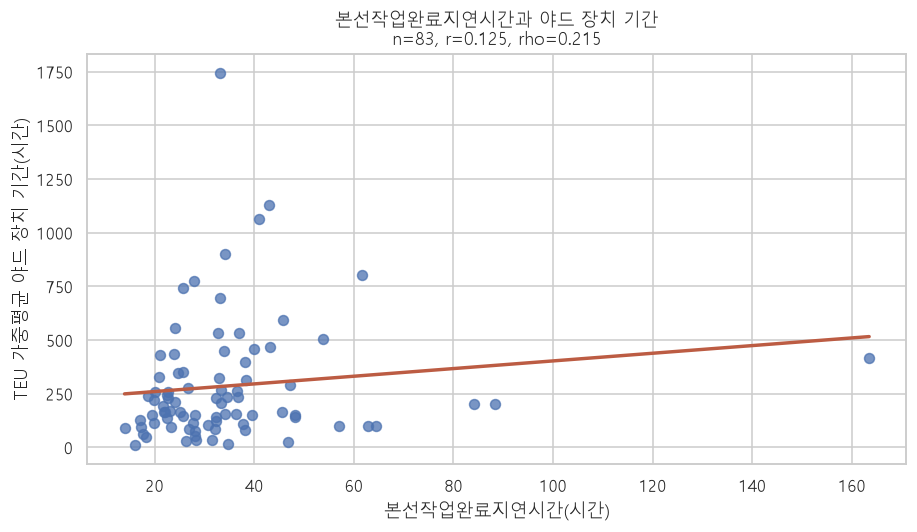

In [6]:
fig,ax=plt.subplots(figsize=(8.5,5))
sample=calls[[X1,Y]].dropna()
row=results.iloc[0]
sns.regplot(data=sample,x=X1,y=Y,ci=None,ax=ax,scatter_kws={'s':42,'alpha':.75},line_kws={'color':'#bc5c43'})
ax.set(xlabel=X1+'(시간)',ylabel='TEU 가중평균 야드 장치 기간(시간)',
       title=f'본선작업완료지연시간과 야드 장치 기간\nn={len(sample)}, r={row["Pearson r"]:.3f}, rho={row["Spearman rho"]:.3f}')
plt.tight_layout(); plt.savefig(OUT/'본선작업완료지연시간_야드장치기간.png',dpi=160,bbox_inches='tight')
plt.show(); plt.close()


## 5. 분석 결과와 해석

다음 요약은 계산 결과에서 직접 생성한다.
유의하지 않은 검정은 관계가 없다는 증명이 아니라, 현재 표본에서 충분한 근거를 확인하지 못했다는 의미다.

In [7]:
row=results.iloc[0]
direction='양' if row['Pearson r']>0 else '음'
inference=(f'유의수준 0.05에서 유의한 {direction}의 선형 상관이 관측되었다.' if row['Pearson p']<.05
           else '유의수준 0.05에서 유의한 선형 상관을 확인하지 못했다.')
display(Markdown(f"분석 대상은 **{len(df)}건·{total_teu:,.0f} TEU, 적하모선 {len(calls)}항차**다. "
                 f"야드 장치 기간은 컨테이너당 평균 {df[Y].mean():.2f}시간, 중앙값 {df[Y].median():.2f}시간이며 "
                 f"TEU 가중평균은 {np.average(df[Y],weights=df['TEU']):.2f}시간이다.\n\n"
                 f"**본선작업완료지연시간**은 {int(row['항차수'])}항차에서 "
                 f"r={row['Pearson r']:.3f}, rho={row['Spearman rho']:.3f}, R²={row['R²']:.3f}였다. "
                 f"Pearson p={row['Pearson p']:.3g}, Spearman p={row['Spearman p']:.3g}다. {inference} "
                 '유의하지 않다는 결과는 관계가 전혀 없다는 증명이 아니다.'))


분석 대상은 **154건·269 TEU, 적하모선 83항차**다. 야드 장치 기간은 컨테이너당 평균 280.80시간, 중앙값 194.57시간이며 TEU 가중평균은 279.34시간이다.

**본선작업완료지연시간**은 83항차에서 r=0.125, rho=0.215, R²=0.016였다. Pearson p=0.262, Spearman p=0.0507다. 유의수준 0.05에서 유의한 선형 상관을 확인하지 못했다. 유의하지 않다는 결과는 관계가 전혀 없다는 증명이 아니다.

### 물류·항만 및 통계 관점의 해석 범위

1. **X은 반입 마감과 관측된 마지막 양하·적하 작업시각 사이의 간격이다.** 사용자가 지정한 정의를 그대로 적용했다.
   최초 예정 본선 작업완료시각과 비교한 값은 아니므로, 본선 작업의 생산성 저하를 직접 나타내지는 않는다.
   연간 전체 명세의 양하·적하 최댓값을 사용한다. 연간 파일 자체의 수집 누락이 있으면 실제 완료시각과 차이가 날 수 있다.
2. **X과 Y는 일부 반출시각을 공유할 수 있다.** X이 적하 반출일시에서 결정된 항차에서는 그 시각과 Y의 개별 반출일시가 연결되므로,
   상관에는 공통 시각과 항차 구성의 영향이 포함될 수 있다. 높은 r나 R²를 인과효과로 확정하지 않는다.
3. **항차 집계 후에도 한계는 남는다.** 본선작업완료시각이 기록된 항차의 관측 범위, 항차 간 공통 운항 조건,
   조회 이후 갱신된 예정시각의 가능성이 남는다. 표본을 DGT 전체 실적으로 확대하지 않는다.

결론적으로 본선작업완료지연시간과 야드 장치 기간의 동반 변화를 평가할 수 있으나,
다음 입항 지연을 포함한 전체 전파 사슬은 본 분석의 상관관계만으로 입증할 수 없다.

## 6. 선석별 자부두환적 작업 물동량

B1·B2·B3의 작업 물동량은 **DGT_SELF_TS.csv에서 2025년 조건을 충족한 자부두환적 표본만** 집계한다.
양하 작업은 해당 컨테이너의 양하모선 선석에, 적하 작업은 적하모선 선석에 연결한다.
총 자부두환적 작업 물동량은 양하 TEU+적하 TEU다.
같은 환적 컨테이너도 양하와 적하는 서로 다른 작업이므로 각각 집계하며,
이 합계를 중복 없는 환적 물동량과 구분한다. 전체 선석의 양하 합계와 적하 합계는 각각 표본 TEU와 같아야 한다.

연간 전체 컨테이너 명세는 이 절의 작업 물동량에 포함하지 않는다.
`DGT_2025_anmual.csv`의 역할은 해당 모선항차 전체의 마지막 작업완료 시각을 제공하는 데 한정한다.
선석별 상관검정 역시 자부두환적 표본을 **적하모선 선석**으로 나누어 수행한다.
독립변수는 본선작업완료지연시간 하나를 유지한다.


In [8]:
# 선석별·화물별 분석에 공통으로 사용하는 집계 함수.
def container_summary(data,label):
    values=data[Y]
    return {'구분':label,'표본수':len(data),'물동량(TEU)':data['TEU'].sum(),
            '평균(시간)':values.mean(),'표준편차(시간)':values.std(),'중앙값(시간)':values.median(),
            'IQR(시간)':values.quantile(.75)-values.quantile(.25),
            'TEU 가중평균(시간)':np.average(values,weights=data['TEU']) if len(data) else np.nan}

def aggregate_calls(data):
    rows=[]
    for key,g in data.groupby('적하모선항차',sort=True):
        assert g[X1].nunique(dropna=False)==1
        rows.append({'적하모선항차':key,'표본수':len(g),'물동량(TEU)':g['TEU'].sum(),
                     Y:np.average(g[Y],weights=g['TEU']),X1:g[X1].iloc[0]})
    return pd.DataFrame(rows,columns=['적하모선항차','표본수','물동량(TEU)',Y,X1])

def stratified_tests(parts):
    rows=[]
    for label,part in parts:
        grouped=aggregate_calls(part)
        for x in [X1]:
            result=correlation(grouped,x)
            result['구분']=label
            rows.append(result)
    return adjusted(pd.DataFrame(rows))



# 자부두환적 표본의 양하·적하 작업만 집계한다.
assert df[['양하_선석','적하_선석']].notna().all().all()
self_unloading=df[['컨테이너번호','방문회차','양하모선항차','양하_선석','TEU']].rename(
    columns={'양하모선항차':'모선항차','양하_선석':'선석'})
self_unloading['작업구분']='양하'
self_loading=df[['컨테이너번호','방문회차','적하모선항차','적하_선석','TEU']].rename(
    columns={'적하모선항차':'모선항차','적하_선석':'선석'})
self_loading['작업구분']='적하'
self_work_events=pd.concat([self_unloading,self_loading],ignore_index=True)
assert not self_work_events.duplicated(['컨테이너번호','방문회차','모선항차','작업구분']).any()
assert len(self_work_events)==2*len(df)
workload=[]
for berth in ['B1','B2','B3']:
    group=self_work_events.loc[self_work_events['선석'].eq(berth)]
    workload.append({'선석':berth,'양하 작업량(TEU)':group.loc[group['작업구분'].eq('양하'),'TEU'].sum(),
                     '적하 작업량(TEU)':group.loc[group['작업구분'].eq('적하'),'TEU'].sum(),
                     '총 작업량(TEU)':group['TEU'].sum(),'작업건수':len(group),
                     '관측 항차수':group['모선항차'].nunique()})
berth_workload=pd.DataFrame(workload)
assert np.isclose(berth_workload['양하 작업량(TEU)'].sum(),total_teu)
assert np.isclose(berth_workload['적하 작업량(TEU)'].sum(),total_teu)
assert np.isclose(berth_workload['총 작업량(TEU)'].sum(),2*total_teu)
table(berth_workload,'표7a_선석별_자부두환적작업물동량')
berth_parts=[(label,df.loc[df['적하_선석'].eq(label)]) for label in ['B1','B2','B3']]
berth_summary=pd.DataFrame([container_summary(part,label) for label,part in berth_parts])
table(berth_summary,'표7b_적하선석별_자부두환적_장치기간')
berth_results=stratified_tests(berth_parts)
table(berth_results[['구분','독립변수','항차수','Pearson r','Spearman rho','R²','Pearson p(Holm)','Spearman p(Holm)','판정']],
      '표8_적하선석별_본선작업완료지연시간_상관검정')
self_work_events.to_csv(OUT/'자부두환적_선석별작업_검산자료.csv',index=False,encoding='utf-8-sig')


표7a_선석별_자부두환적작업물동량


선석,양하 작업량(TEU),적하 작업량(TEU),총 작업량(TEU),작업건수,관측 항차수
B1,55.000,69.000,124.000,72,35
B2,131.000,100.000,231.000,130,63
B3,83.000,100.000,183.000,106,46


표7b_적하선석별_자부두환적_장치기간


구분,표본수,물동량(TEU),평균(시간),표준편차(시간),중앙값(시간),IQR(시간),TEU 가중평균(시간)
B1,40,69.000,301.384,244.029,265.242,364.175,294.463
B2,59,100.000,288.107,309.854,165.483,296.983,290.851
B3,55,100.000,258.003,269.727,195.567,154.558,257.383


표8_적하선석별_본선작업완료지연시간_상관검정


구분,독립변수,항차수,Pearson r,Spearman rho,R²,Pearson p(Holm),Spearman p(Holm),판정
B1,본선작업완료지연시간,19,-0.263,-0.279,0.069,0.677,0.474,
B2,본선작업완료지연시간,34,0.140,0.446,0.020,0.677,0.0245,
B3,본선작업완료지연시간,30,0.228,0.223,0.052,0.677,0.474,


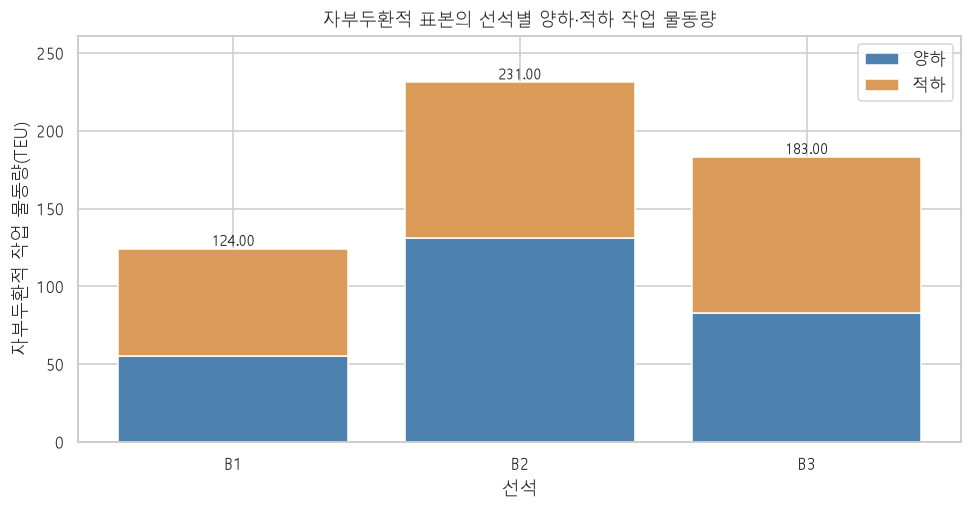

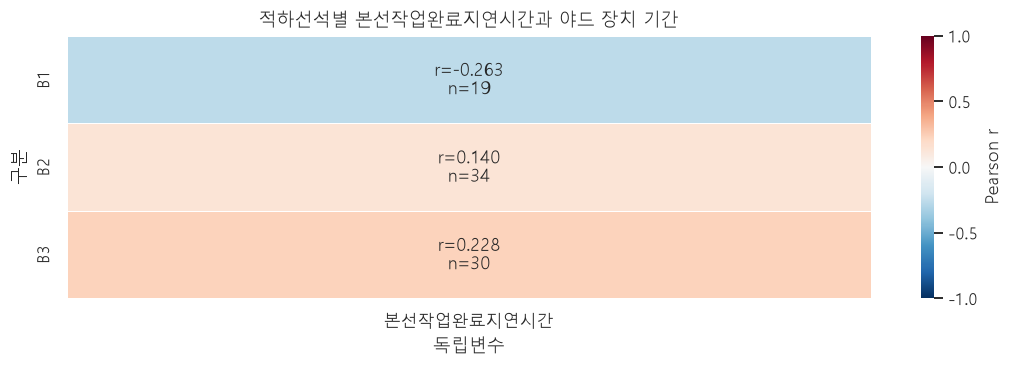

In [9]:
def plot_stratified_correlations(result,order,title,filename):
    fig,ax=plt.subplots(figsize=(10, max(3.5,len(order)*.55)))
    matrix=result.pivot(index='구분',columns='독립변수',values='Pearson r').reindex(index=order,columns=[X1])
    ns=result.pivot(index='구분',columns='독립변수',values='항차수').reindex(index=order,columns=[X1])
    labels=matrix.copy().astype(object)
    for row in order:
        for x in [X1]:
            value=matrix.loc[row,x]
            labels.loc[row,x]=f'r={value:.3f}\nn={int(ns.loc[row,x])}' if pd.notna(value) else ''
    sns.heatmap(matrix,annot=labels,fmt='',cmap='RdBu_r',vmin=-1,vmax=1,center=0,
                linewidths=.5,ax=ax,cbar_kws={'label':'Pearson r'})
    for i,row in enumerate(order):
        for j,x in enumerate([X1]):
            if pd.isna(matrix.loc[row,x]): ax.text(j+.5,i+.5,f'검정 불가\nn={int(ns.loc[row,x])}',ha='center',va='center',fontsize=9)
    ax.set(title=title,xlabel='독립변수',ylabel='구분')
    plt.tight_layout()
    plt.savefig(OUT/filename,dpi=160,bbox_inches='tight')
    plt.show(); plt.close()


fig,ax=plt.subplots(figsize=(9,4.8))
ax.bar(berth_workload['선석'],berth_workload['양하 작업량(TEU)'],label='양하',color='#4d82b0')
ax.bar(berth_workload['선석'],berth_workload['적하 작업량(TEU)'],bottom=berth_workload['양하 작업량(TEU)'],label='적하',color='#d99b57')
for _,row in berth_workload.iterrows():
    ax.text(row['선석'],row['총 작업량(TEU)'],f"{row['총 작업량(TEU)']:,.2f}",ha='center',va='bottom',fontsize=10)
ax.set(title='자부두환적 표본의 선석별 양하·적하 작업 물동량',xlabel='선석',ylabel='자부두환적 작업 물동량(TEU)')
ax.set_ylim(0,berth_workload['총 작업량(TEU)'].max()*1.13)
ax.legend()
plt.tight_layout(); plt.savefig(OUT/'선석별_총본선작업물동량.png',dpi=160,bbox_inches='tight')
plt.show(); plt.close()
plot_stratified_correlations(berth_results,['B1','B2','B3'],'적하선석별 본선작업완료지연시간과 야드 장치 기간',
                            '선석별_본선작업완료지연시간_상관.png')


In [10]:

largest=berth_workload.loc[berth_workload['총 작업량(TEU)'].idxmax()]
valid=berth_results['Pearson p(Holm)'].notna().sum()
significant=berth_results['Pearson p(Holm)'].lt(.05).sum()
display(Markdown(f"**선석별 해석.** 자부두환적 표본은 **{len(df)}건·{total_teu:,.0f} TEU**다. "
                 f"양하와 적하를 각각 집계한 본선 작업량은 {2*total_teu:,.0f} TEU이며, "
                 f"총 작업 물동량이 가장 큰 선석은 **{largest['선석']}({largest['총 작업량(TEU)']:,.0f} TEU)**였다. "
                 '이 값은 일반 수출입 컨테이너를 포함한 DGT 전체 물동량이 아니다. '
                 f"선석별 Pearson 검정은 {valid}개가 가능했고 Holm 보정 후 유의한 조합은 {significant}개였다. "
                 '연간 전체 명세는 작업완료 시각 산정에만 사용하고 이 절의 물동량에는 포함하지 않았다.'))


**선석별 해석.** 자부두환적 표본은 **154건·269 TEU**다. 양하와 적하를 각각 집계한 본선 작업량은 538 TEU이며, 총 작업 물동량이 가장 큰 선석은 **B2(231 TEU)**였다. 이 값은 일반 수출입 컨테이너를 포함한 DGT 전체 물동량이 아니다. 선석별 Pearson 검정은 3개가 가능했고 Holm 보정 후 유의한 조합은 0개였다. 연간 전체 명세는 작업완료 시각 산정에만 사용하고 이 절의 물동량에는 포함하지 않았다.

## 7. 화물별 분석: 적컨·공컨·냉동·위험물

냉동은 냉동 형식(RF) 또는 온도 설정이 있는 컨테이너, 위험물은 위험물 등급·번호가 있는 컨테이너로 구분한다.
적컨(F)·공컨(M)은 냉동·위험물에 해당하지 않는 일반 화물로 정의한다.
냉동과 위험물에 동시에 해당하면 두 특성을 모두 나타내므로 각 집단에 포함하고 중복 표본수를 표시한다.
따라서 중복이 있는 자료에서는 네 유형의 TEU를 전체 물동량으로 단순 합산하지 않는다.

각 화물 집단 안에서 적하모선항차당 한 점으로 집계하고, 본선작업완료지연시간과 TEU 가중평균 장치기간을 검정한다.
화물별 최대 4개 검정을 Pearson·Spearman 각각 Holm 보정한다.
선석별 분석과 화물별 분석은 별도의 비교 묶음이며, 선석×화물의 교차 세분화는 수행하지 않는다.

In [11]:
features=raw[['명세.fullEmpty','명세.cntrType','명세.temperature','명세.imdg','명세.unno']].copy()
features['원자료행']=np.arange(2,len(features)+2)
df=df.merge(features,on='원자료행',how='left',validate='one_to_one')
def present(series): return series.astype('string').fillna('').str.strip().ne('')
cold=df['명세.cntrType'].eq('RF')|present(df['명세.temperature'])
danger=present(df['명세.imdg'])|present(df['명세.unno'])
full=df['명세.fullEmpty'].astype('string').str.strip().str.upper()
cargo_flags={'적컨':~(cold|danger)&full.eq('F'),'공컨':~(cold|danger)&full.eq('M'),
             '냉동':cold,'위험물':danger}
cargo_parts=[(label,df.loc[flag]) for label,flag in cargo_flags.items()]
overlap=int((cold&danger).sum())
unclassified=int((~pd.DataFrame(cargo_flags).any(axis=1)).sum())
assert unclassified==0,'분류되지 않은 화물이 있어 상태 코드 확인이 필요합니다.'
if overlap==0:
    assert sum(len(part) for _,part in cargo_parts)==len(df)
    assert np.isclose(sum(part['TEU'].sum() for _,part in cargo_parts),total_teu)
print('냉동·위험물 동시 해당:',overlap,'건 / 미분류:',unclassified,'건')
cargo_summary=pd.DataFrame([container_summary(part,label) for label,part in cargo_parts])
table(cargo_summary,'표9_화물별_장치기간')
cargo_results=stratified_tests(cargo_parts)
table(cargo_results[['구분','독립변수','항차수','Pearson r','Spearman rho','R²','Pearson p(Holm)','Spearman p(Holm)','판정']],
      '표10_화물별_본선작업완료지연시간_상관검정')

냉동·위험물 동시 해당: 0 건 / 미분류: 0 건
표9_화물별_장치기간


구분,표본수,물동량(TEU),평균(시간),표준편차(시간),중앙값(시간),IQR(시간),TEU 가중평균(시간)
적컨,108,191.000,205.117,179.675,152.792,163.742,194.874
공컨,25,48.000,642.940,397.783,521.117,158.317,644.211
냉동,12,21.000,265.599,184.398,237.275,35.725,246.082
위험물,9,9.000,203.393,189.904,115.250,399.450,203.393


표10_화물별_본선작업완료지연시간_상관검정

구분,독립변수,항차수,Pearson r,Spearman rho,R²,Pearson p(Holm),Spearman p(Holm),판정
적컨,본선작업완료지연시간,64,0.097,0.111,0.009,1,1,
공컨,본선작업완료지연시간,11,0.208,0.0364,0.043,1,1,
냉동,본선작업완료지연시간,8,0.220,0.595,0.048,1,0.478,
위험물,본선작업완료지연시간,4,-0.491,-0.2,0.241,1,1,


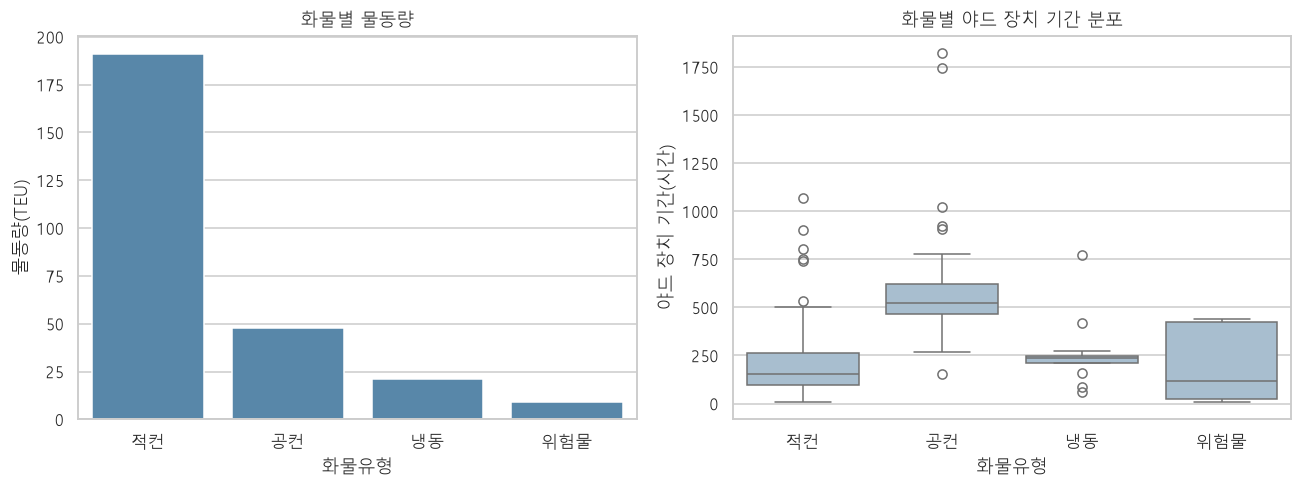

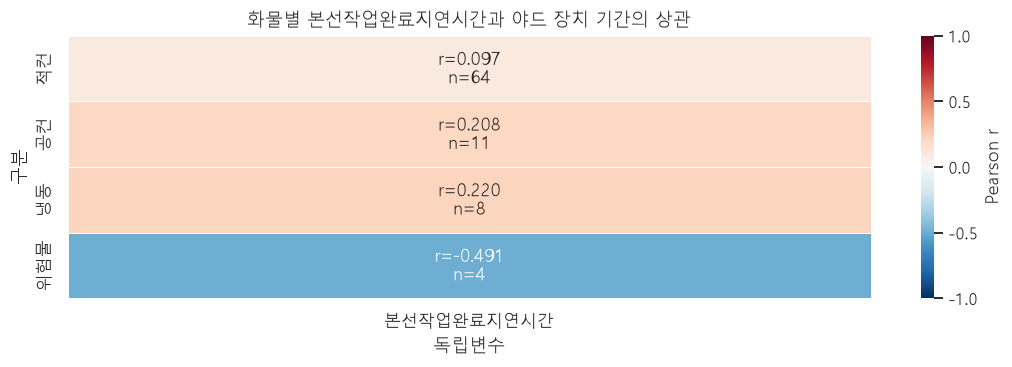

In [12]:
plot_cargo=pd.concat([part.assign(화물유형=label) for label,part in cargo_parts],ignore_index=True)
cargo_order=list(cargo_flags)
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
sns.barplot(data=cargo_summary,x='구분',y='물동량(TEU)',order=cargo_order,ax=axes[0],errorbar=None,color='#4b89b6')
axes[0].set(title='화물별 물동량',xlabel='화물유형',ylabel='물동량(TEU)')
sns.boxplot(data=plot_cargo,x='화물유형',y=Y,order=cargo_order,ax=axes[1],color='#a2bfd5')
axes[1].set(title='화물별 야드 장치 기간 분포',xlabel='화물유형',ylabel='야드 장치 기간(시간)')
plt.tight_layout()
plt.savefig(OUT/'화물별_물동량과장치기간.png',dpi=160,bbox_inches='tight')
plt.show(); plt.close()
plot_stratified_correlations(cargo_results,cargo_order,'화물별 본선작업완료지연시간과 야드 장치 기간의 상관',
                            '화물별_본선작업완료지연시간_상관.png')

In [13]:
longest_cargo=cargo_summary.loc[cargo_summary['TEU 가중평균(시간)'].idxmax()]
cargo_valid=cargo_results['Pearson p(Holm)'].notna().sum()
cargo_sig=cargo_results['Pearson p(Holm)'].lt(.05).sum()
display(Markdown(f"**화물별 해석.** TEU 가중평균 장치기간이 가장 긴 화물은 **{longest_cargo['구분']}**로 "
                 f"{longest_cargo['TEU 가중평균(시간)']:.2f}시간이었다. "
                 f"본선작업완료지연시간의 Pearson 검정은 {cargo_valid}개 조합에서 가능했고 Holm 보정 후 유의한 조합은 {cargo_sig}개였다. "
                 '냉동·위험물 등 작은 표본에서는 항차수가 적어 상관 추정의 불확실성이 크다. '
                 '검정 불가를 관계가 없다는 뜻으로 해석하지 않는다. '
                 '유형 간 장치기간 차이는 관측 특성이며, 이번 분석은 각 유형 안에서 본선작업완료지연시간의 관련성을 확인하는 범위다.'))


# 선석별·화물별 항차 집계값을 검산할 수 있도록 보존한다.
berth_call_data=pd.concat([aggregate_calls(part).assign(적하선석=label) for label,part in berth_parts],ignore_index=True)
cargo_call_data=pd.concat([aggregate_calls(part).assign(화물유형=label) for label,part in cargo_parts],ignore_index=True)
assert not berth_call_data.duplicated(['적하선석','적하모선항차']).any()
assert not cargo_call_data.duplicated(['화물유형','적하모선항차']).any()
assert np.isclose(berth_call_data['물동량(TEU)'].sum(),total_teu)
berth_call_data.to_csv(OUT/'선석별_항차단위_분석자료.csv',index=False,encoding='utf-8-sig')
cargo_call_data.to_csv(OUT/'화물별_항차단위_분석자료.csv',index=False,encoding='utf-8-sig')


**화물별 해석.** TEU 가중평균 장치기간이 가장 긴 화물은 **공컨**로 644.21시간이었다. 본선작업완료지연시간의 Pearson 검정은 4개 조합에서 가능했고 Holm 보정 후 유의한 조합은 0개였다. 냉동·위험물 등 작은 표본에서는 항차수가 적어 상관 추정의 불확실성이 크다. 검정 불가를 관계가 없다는 뜻으로 해석하지 않는다. 유형 간 장치기간 차이는 관측 특성이며, 이번 분석은 각 유형 안에서 본선작업완료지연시간의 관련성을 확인하는 범위다.

## 부록. 계산 검증과 재실행

노트북의 모든 분석 코드는 이 파일 안에 포함되어 있다.
다른 노트북이나 외부 Python 분석 파일을 실행하지 않는다.
`DGT_SELF_TS.csv`와 선석배정현황은 노트북과 같은 폴더 또는 `analysis`에 두고,
연간 파일은 같은 폴더 또는 `data/DATA2/DGT_2025_anmual.csv`에 둔 뒤 전체 실행한다.
부록의 환경 버전과 동일한 버전을 사용하면 수치를 재현할 수 있다.

In [14]:
from datetime import datetime
from statistics import mean, correlation as independent_r
assert not df.duplicated(['컨테이너번호','방문회차']).any()
assert df['반입일시'].dt.year.eq(2025).all() and df['반출일시'].dt.year.eq(2025).all()
assert df['양하_실제시각_2025'].all() and df['적하_실제시각_2025'].all()
assert df[Y].ge(0).all() and df['TEU'].isin(list(TEU_MAP.values())).all()
# pandas 이벤트 집계와 별도로 원자료의 두 방향 시각을 한 번 순회하여 검산한다.
independent_max={}
for side,key,time_col in [('in','양하모선항차','반입일시'),('out','적하모선항차','반출일시')]:
    for mode,vessel,stamp in zip(annual[side+'.mode'],annual[key],annual[time_col]):
        if mode=='S' and vessel is not None and pd.notna(stamp):
            if vessel not in independent_max or stamp>independent_max[vessel]: independent_max[vessel]=stamp
for _,row in operation.dropna(subset=[X1]).iterrows():
    maximum=independent_max[row['모선항차']]
    assert maximum==row['마지막컨테이너작업완료일시']
    assert np.isclose(row[X1],(maximum-row['반입마감일시']).total_seconds()/3600)
for x in [X1]:
    sample=calls[[x,Y]].dropna()
    if sample[x].nunique()>1:
        assert np.isclose(independent_r(sample[x],sample[Y]),results.loc[results['독립변수'].eq(x),'Pearson r'].iloc[0])
versions={p:metadata.version(p) for p in ['numpy','pandas','scipy','matplotlib','seaborn','statsmodels','openpyxl','nbformat','nbclient','ipykernel']}
def file_hash(path):
    with path.open('rb') as stream: return hashlib.file_digest(stream,'sha256').hexdigest()
manifest=pd.DataFrame([{'원자료':p.name,'SHA256':file_hash(p)} for p in [csv_path,xlsx_path,annual_path]])
table(manifest,'부록_원자료해시')
print('Python:',platform.python_version())
print('패키지 버전:',versions)
print('검증: 단일 지표의 정의·연도·TEU·중복·항차 집계·상관계수 독립 재계산 통과')
(OUT/'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n',encoding='utf-8')
calls.to_csv(OUT/'항차별_본선작업완료지연시간_분석자료.csv',index=False,encoding='utf-8-sig')
audit={'분석건수':len(df),'TEU':float(total_teu),'적하모선항차수':len(calls),
       '선석별자부두환적작업TEU':float(berth_workload['총 작업량(TEU)'].sum()),'지표정의':[X1],'결과':results.to_dict(orient='records')}
(OUT/'검증요약.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2),encoding='utf-8')
# 마지막 작업시각을 구성한 양하·적하 이벤트와 집계값을 검토할 수 있도록 보존한다.

operation[['모선항차','마지막컨테이너작업완료일시','반입마감일시',X1]].to_csv(OUT/'항차별_마지막작업완료_검산.csv',index=False,encoding='utf-8-sig')


부록_원자료해시


원자료,SHA256
DGT_SELF_TS.csv,4ba6cb27756b51174b94a3263e9231a9fd155b7fa0e2e4177328e3c827ace1bf
DGT_2025_선석배정현황.xlsx,81eac08be4959f96133cef174690132915eb4795dd3641fa65dcaa3ea472506a
DGT_2025_anmual.csv,810a71b6d350ccb5643521234e85b6333ae15a292f1106ab8443ccede28847e6


Python: 3.12.14
패키지 버전: {'numpy': '2.5.4', 'pandas': '3.1.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'statsmodels': '0.15.0', 'openpyxl': '3.1.5', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'ipykernel': '7.4.0'}
검증: 단일 지표의 정의·연도·TEU·중복·항차 집계·상관계수 독립 재계산 통과


### 출처

- 컨테이너 반입·장치·반출, 화물 특성과 양하·적하모선 선석·실제 시각: `DGT_SELF_TS.csv`.
- 항차 전체 마지막 컨테이너 작업완료 시각 계산 전용: `data/DATA2/DGT_2025_anmual.csv`.
- 반입마감일시·선석: `DGT_2025_선석배정현황.xlsx`, `2025 선석배정현황` 시트.
- 변수 정의와 분석 범위: 이번 요청에서 지정한 단일 작업 지표 및 2025년 필터 조건.

기존 보고서의 재항시간, 예정작업시간, 작업지연시간 등은 본 분석의 변수로 사용하지 않았다.